## OBS: Meu notebook esta com a memória ruim então esta sendo bem dificil rodar os códigos e a mensagem "kernel died unexpectedly" aparece toda hora, consegui rodar um pouco da ultima parte do projeto depois do modelo 9 - Bert, mas a mensagem começou a aparecer com mais contânscia e esta sendo dificil concluir essa projeto! 

# Instrução do Projeto

A Film Junky Union, uma nova comunidade para entusiastas de filmes clássicos, está desenvolvendo um sistema para filtrar e categorizar resenhas de filmes. O objetivo é treinar um modelo para detectar automaticamente resenhas negativas. Você usará um conjunto de dados de resenhas de filmes do IMDB com rotulagem de polaridade para criar um modelo para classificar resenhas como positivas e negativas. Ele precisará ter um valor F1 de pelo menos 0,85.

## Inicialização

In [1]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# a próxima linha fornece gráficos de melhor qualidade em telas HiDPI
%config InlineBackend.figure_format = 'retina'

plt.style.use('seaborn')

In [3]:
# isso é para usar progress_apply, leia mais em https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Carregar Dados

In [4]:
df_reviews = pd.read_csv('/datasets/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [5]:
display(df_reviews.head())
df_reviews.info()

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  int64  
dtypes: Int64(1),

In [6]:
df_reviews.shape

(47331, 17)

In [7]:
df_reviews.isna().sum()

tconst             0
title_type         0
primary_title      0
original_title     0
start_year         0
end_year           0
runtime_minutes    0
is_adult           0
genres             0
average_rating     2
votes              2
review             0
rating             0
sp                 0
pos                0
ds_part            0
idx                0
dtype: int64

In [8]:
df_reviews['ds_part'].value_counts()

train    23796
test     23535
Name: ds_part, dtype: int64

In [9]:
df_reviews['pos'].value_counts()
df_reviews['pos'].value_counts(normalize=True) * 100

0    50.104583
1    49.895417
Name: pos, dtype: float64

## AED

Distribuição das classes

resultado:

0 → 50,1046%

1 → 49,8954%

Isso é praticamente uma divisão 50/50.

Portanto, podemos concluir que:

O conjunto de dados está muito bem balanceado entre avaliações negativas e positivas. Não há um desequilíbrio significativo entre as classes, portanto não será necessário aplicar técnicas de balanceamento como oversampling ou undersampling.

Vamos verificar o número de filmes e resenhas ao longo dos anos.

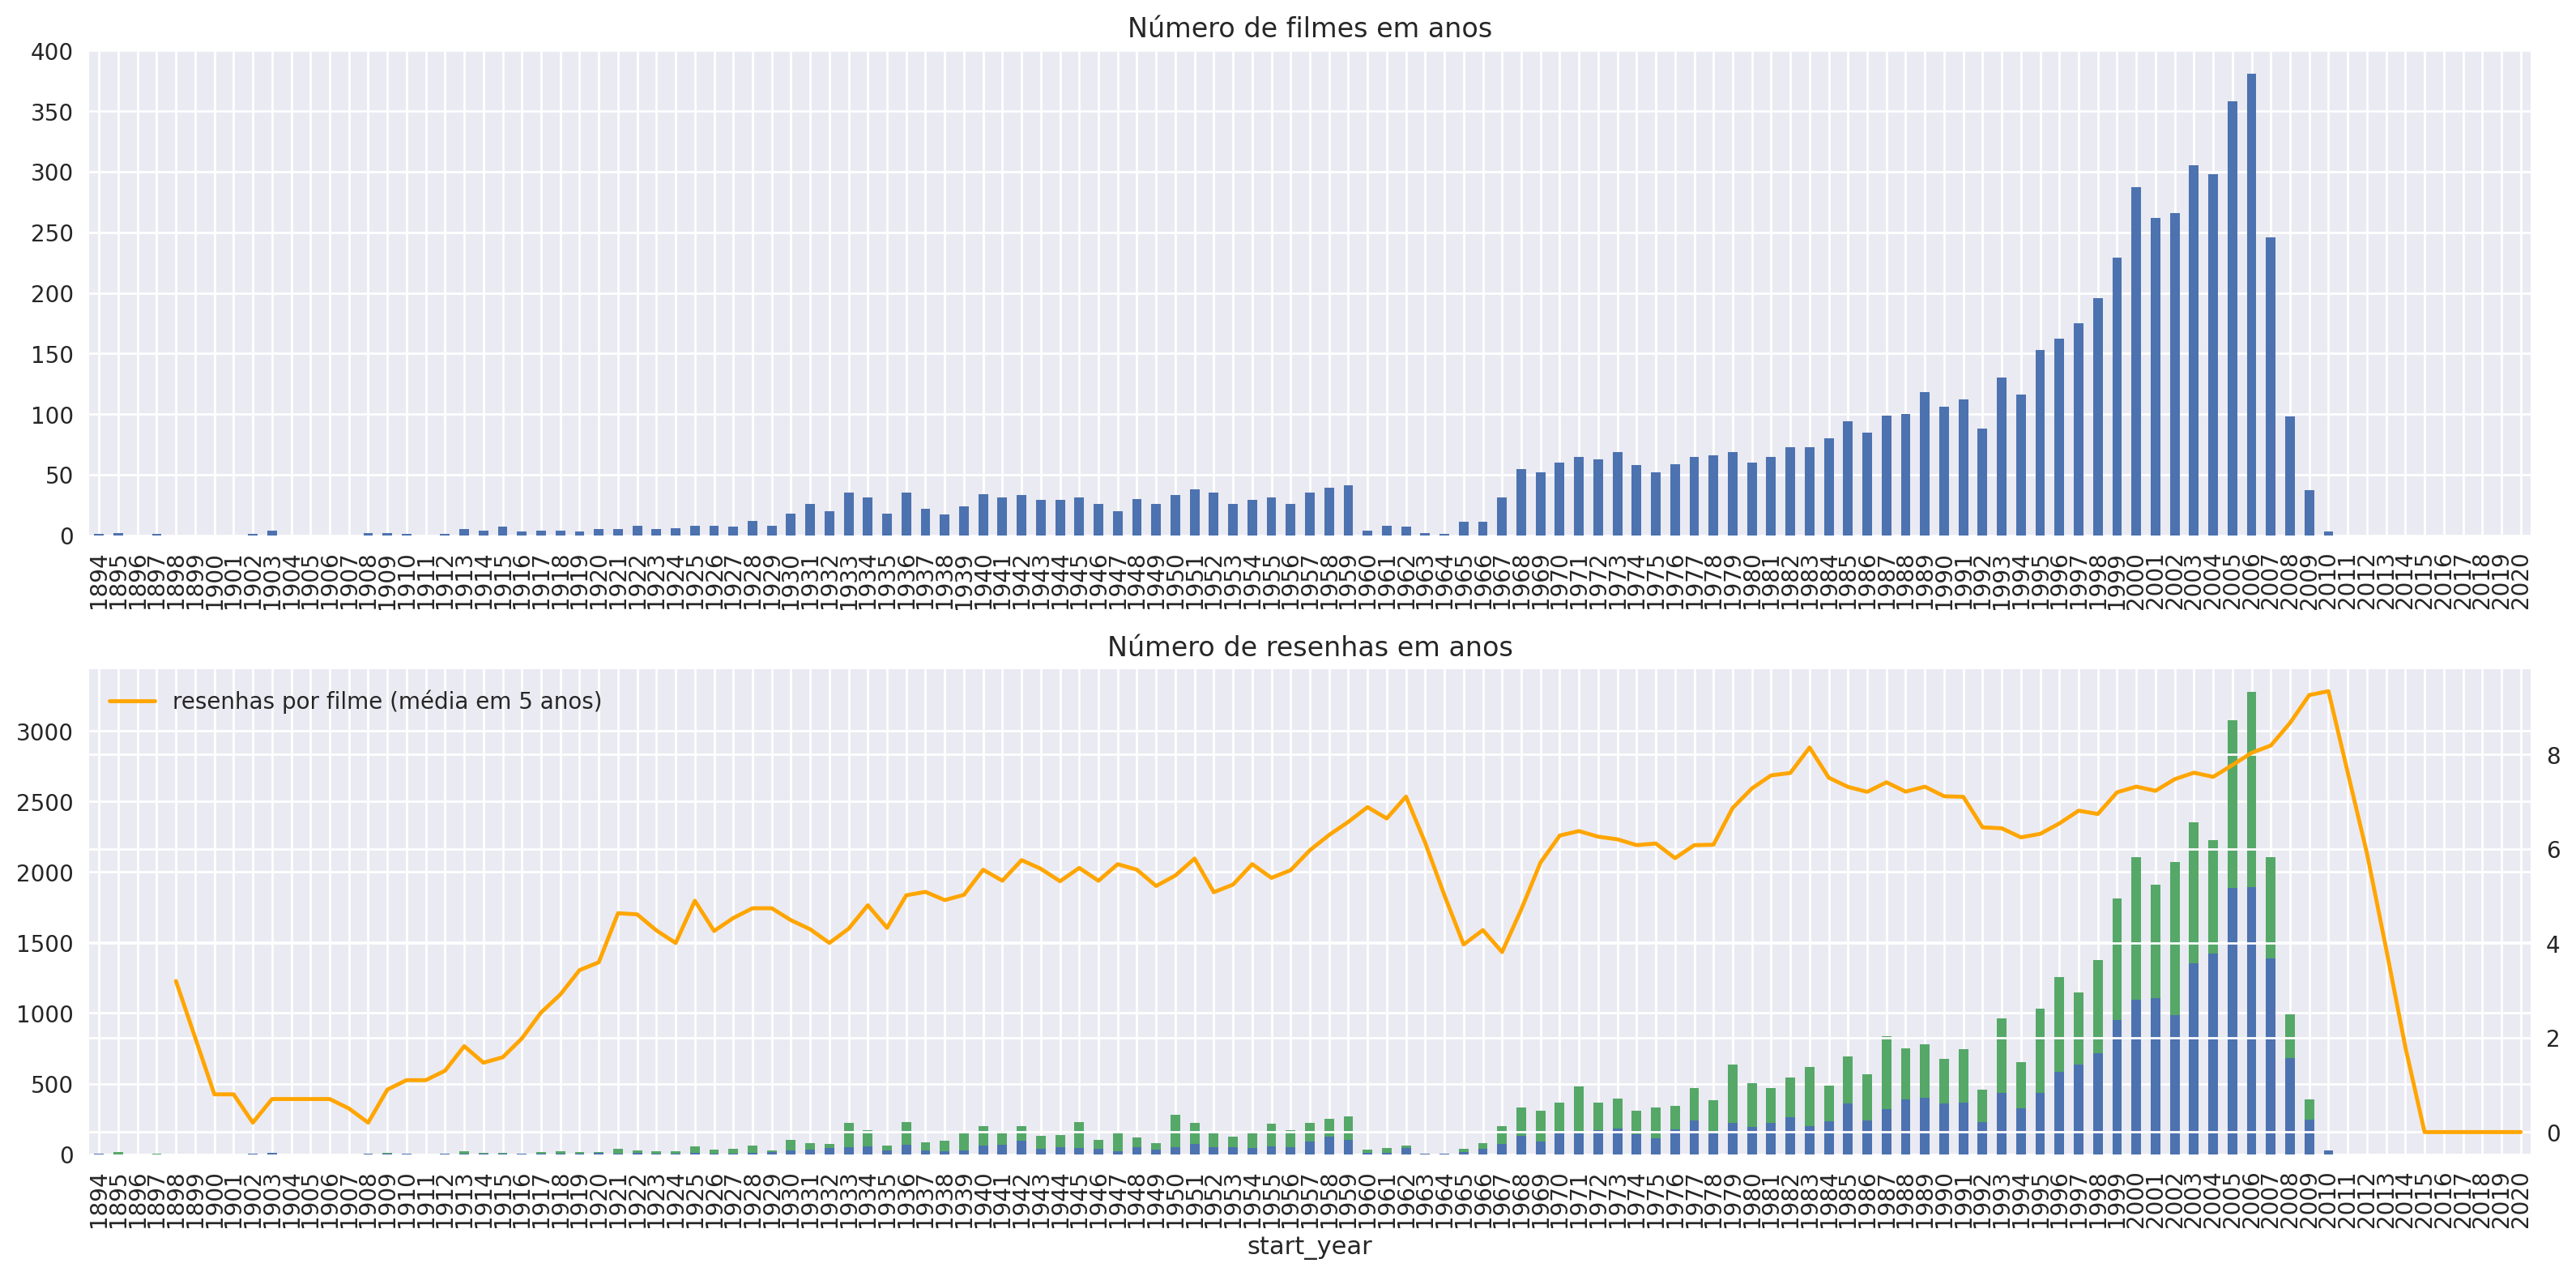

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de filmes em anos')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='resenhas por filme (média em 5 anos)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de resenhas em anos')

fig.tight_layout()

Vamos verificar a distribuição do número de resenhas por filme com a contagem exata e o EDK (Estimativa de densidade kernel - só para saber como pode diferir da contagem exata)

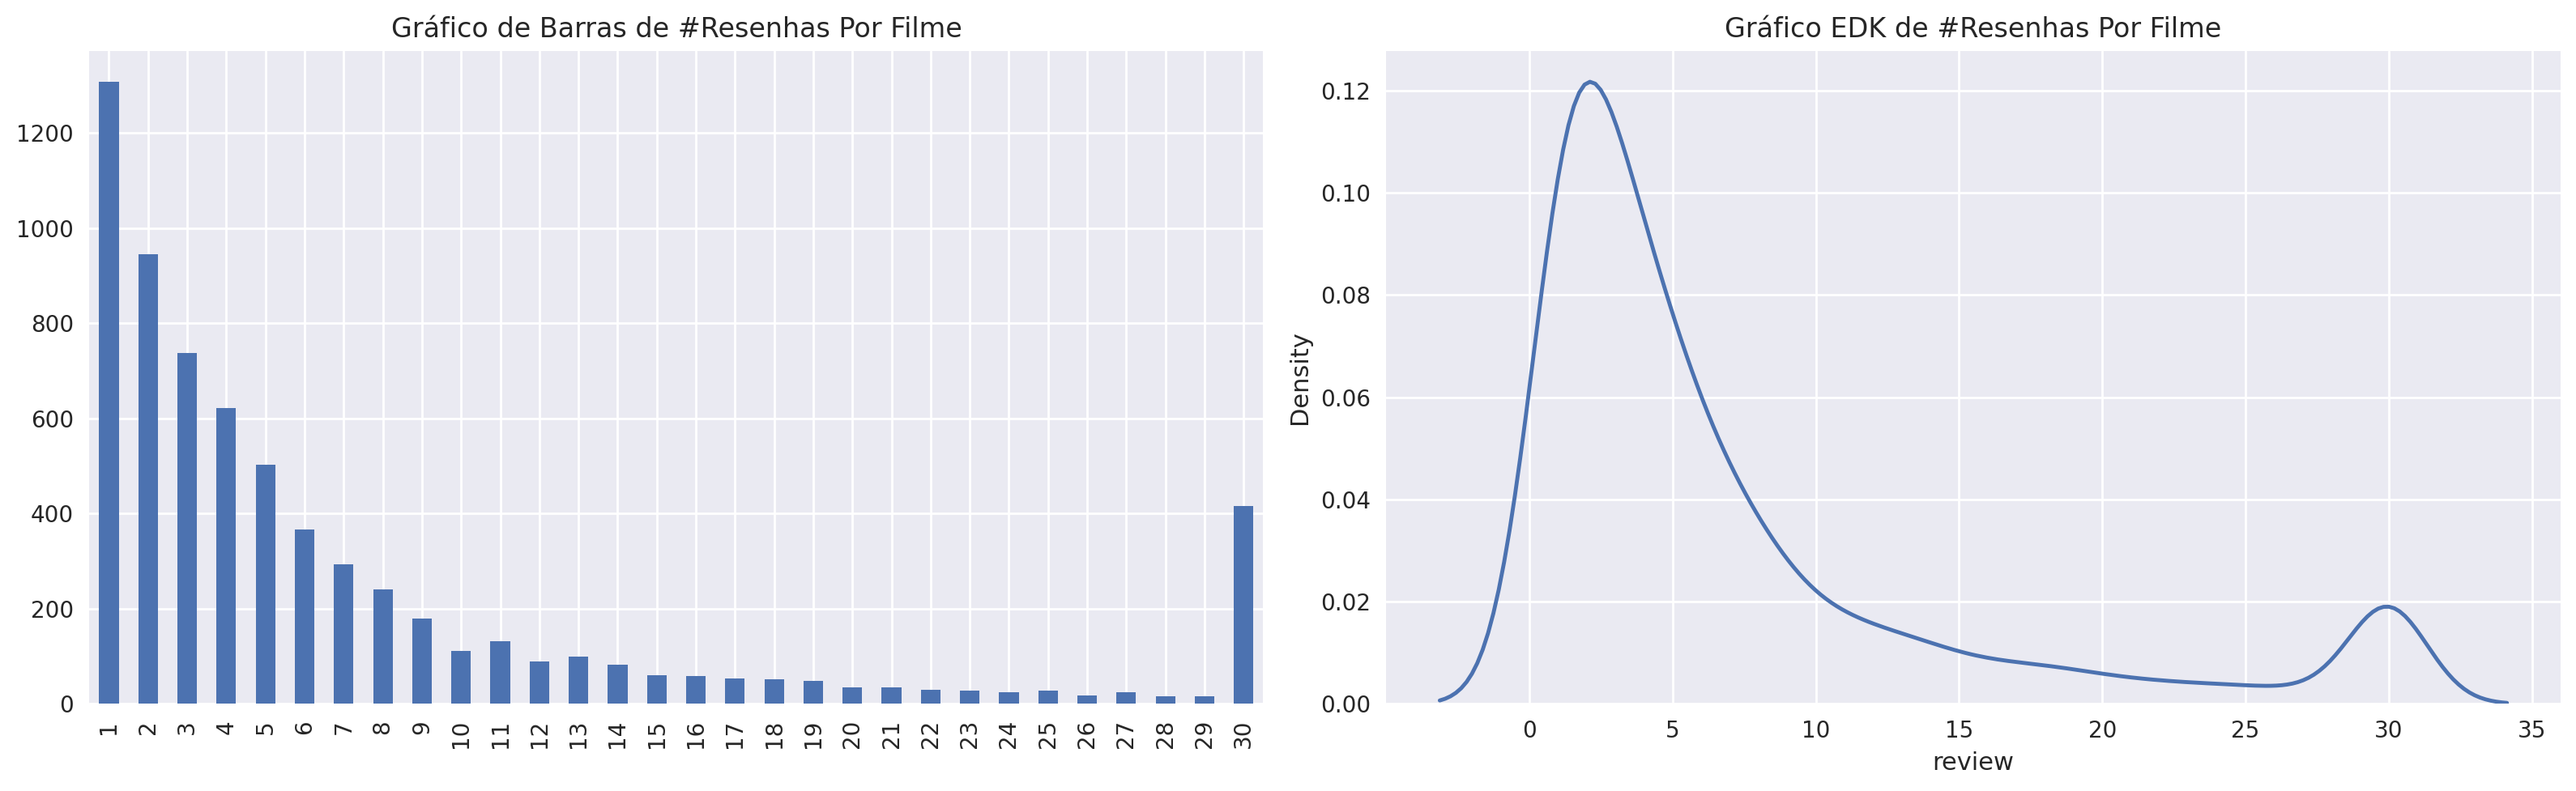

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de Barras de #Resenhas Por Filme')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico EDK de #Resenhas Por Filme')

fig.tight_layout()

In [12]:
df_reviews['pos'].value_counts()

0    23715
1    23616
Name: pos, dtype: int64

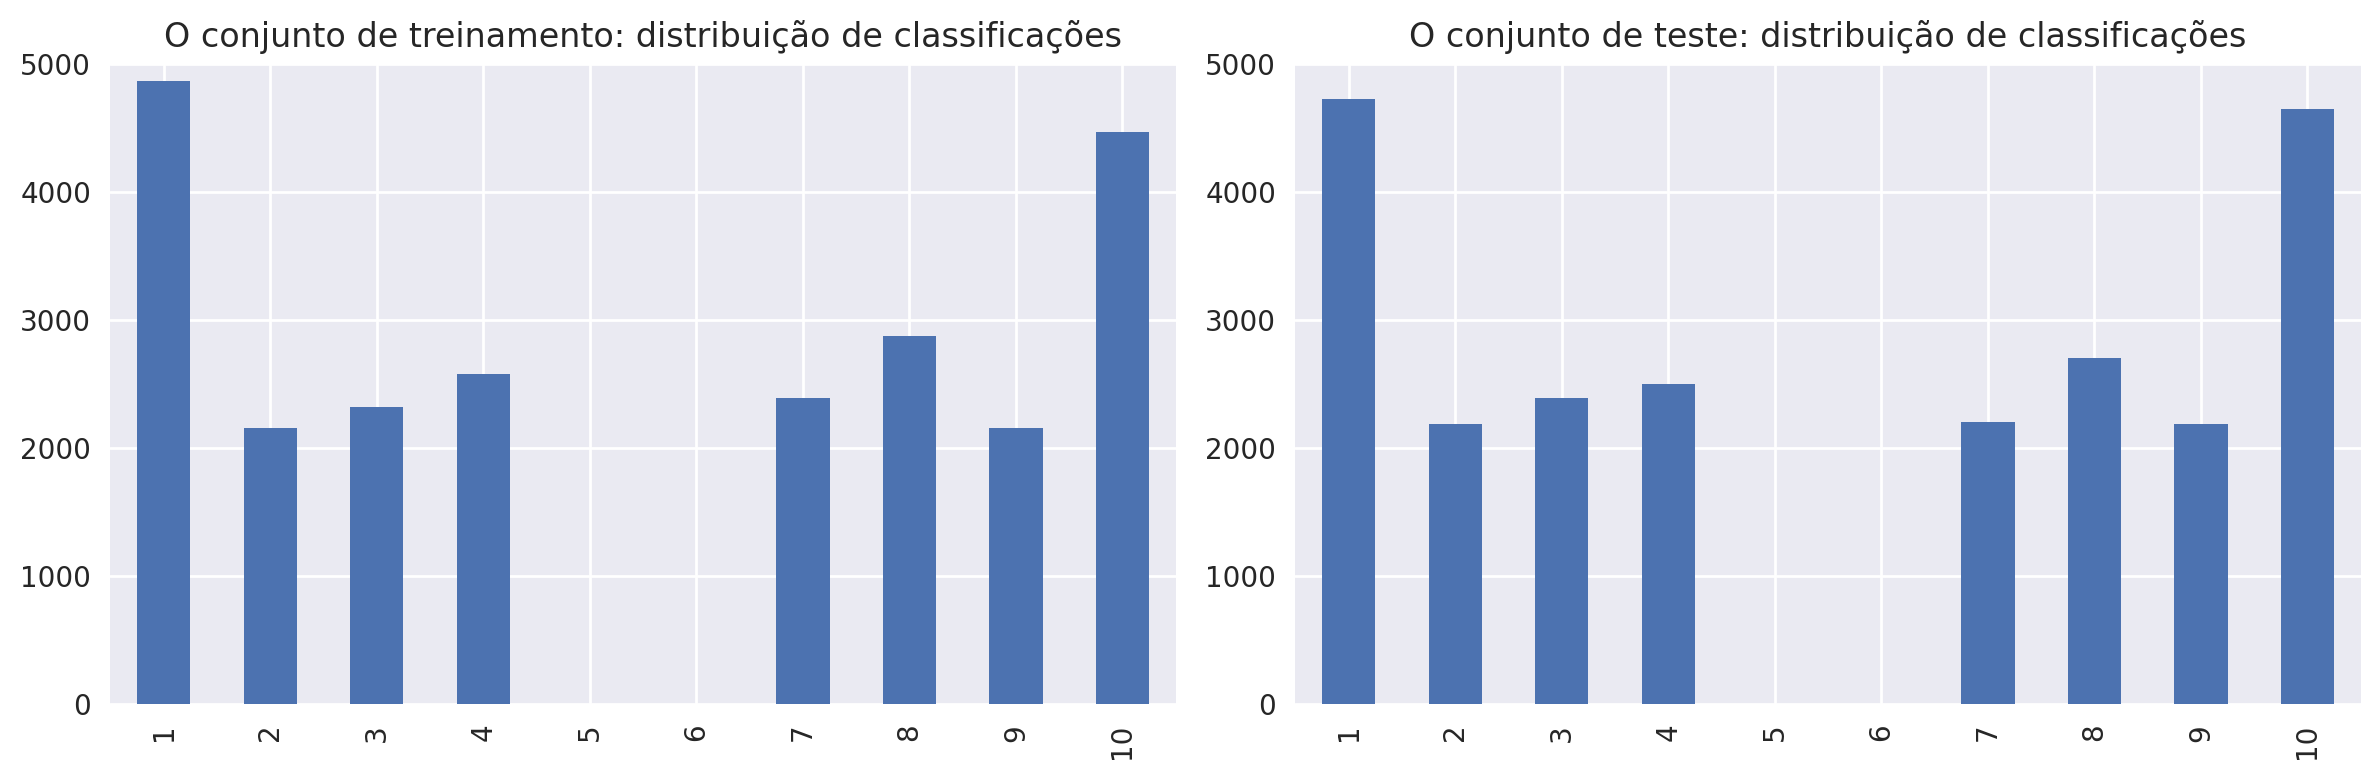

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de treinamento: distribuição de classificações')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('O conjunto de teste: distribuição de classificações')

fig.tight_layout()

Distribuição de resenhas negativas e positivas ao longo dos anos para duas partes do conjunto de dados

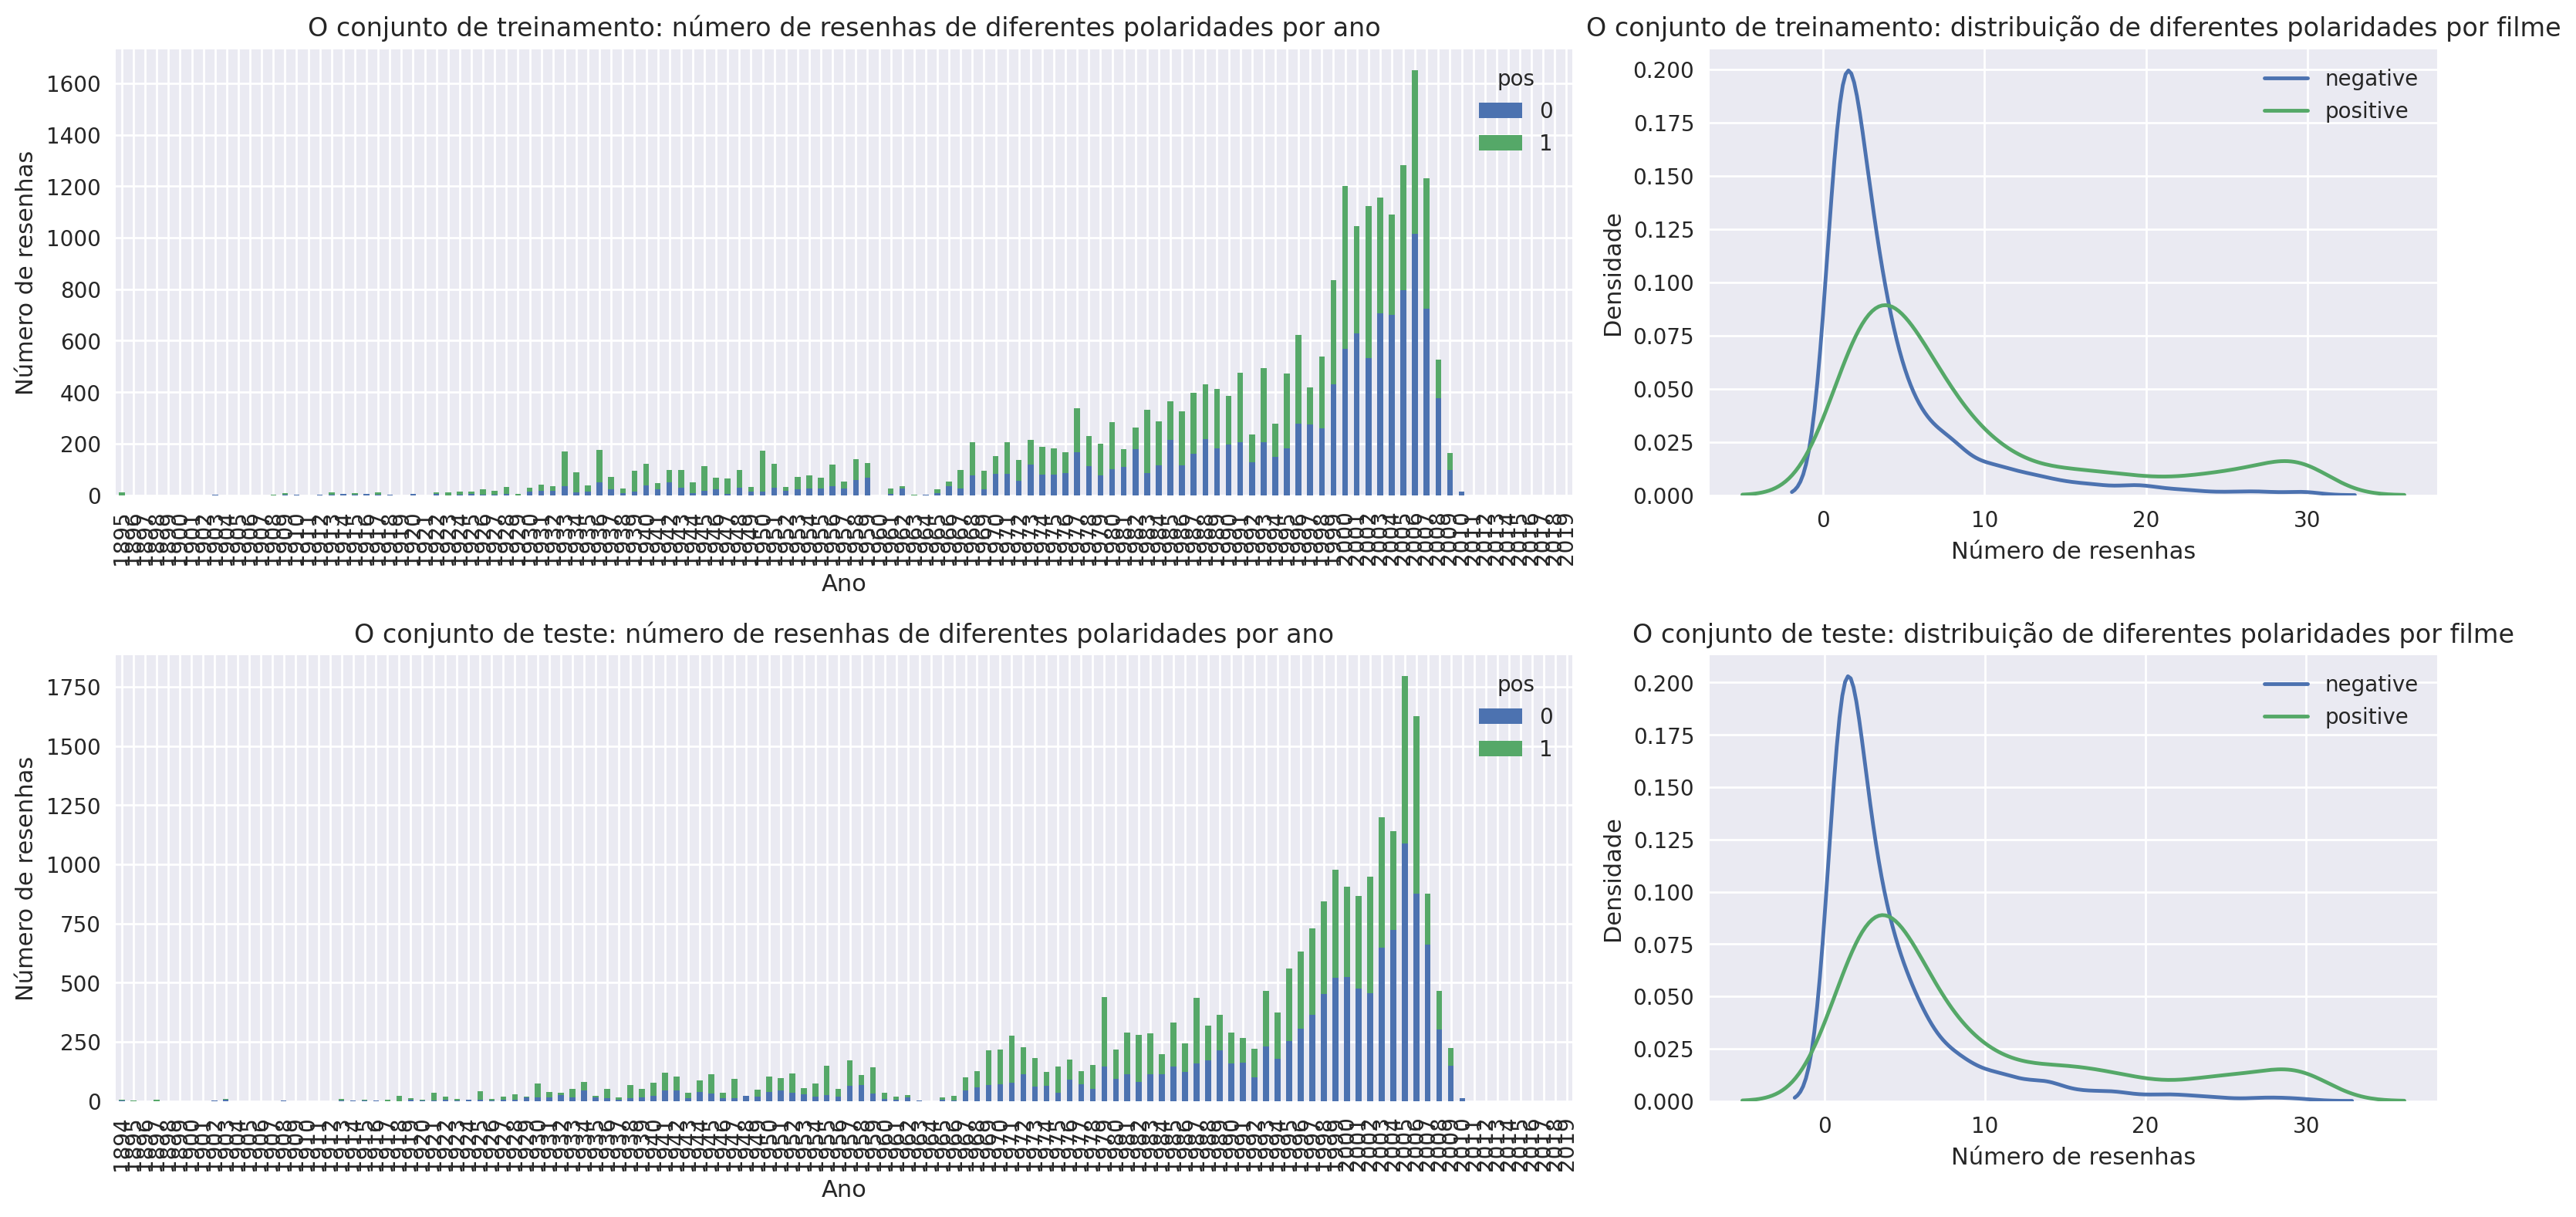

In [14]:
fig, axs = plt.subplots(
    2, 2,
    figsize=(16, 8),
    gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1))
)

# Treinamento - polaridade por ano
ax = axs[0][0]

dft = (
    df_reviews.query('ds_part == "train"')
    .groupby(['start_year', 'pos'])['pos']
    .count()
    .unstack()
)

dft.index = dft.index.astype('int')

dft = dft.reindex(
    index=np.arange(dft.index.min(), max(dft.index.max(), 2020))
).fillna(0)

dft.plot(kind='bar', stacked=True, ax=ax)

ax.set_title(
    'O conjunto de treinamento: número de resenhas de diferentes polaridades por ano'
)
ax.set_xlabel('Ano')
ax.set_ylabel('Número de resenhas')


# Treinamento - distribuição por filme
ax = axs[0][1]

dft = (
    df_reviews.query('ds_part == "train"')
    .groupby(['tconst', 'pos'])['pos']
    .count()
    .unstack()
)

sns.kdeplot(dft[0], label='negative', ax=ax)
sns.kdeplot(dft[1], label='positive', ax=ax)

ax.legend()
ax.set_title(
    'O conjunto de treinamento: distribuição de diferentes polaridades por filme'
)
ax.set_xlabel('Número de resenhas')
ax.set_ylabel('Densidade')


# Teste - polaridade por ano
ax = axs[1][0]

dft = (
    df_reviews.query('ds_part == "test"')
    .groupby(['start_year', 'pos'])['pos']
    .count()
    .unstack()
)

dft.index = dft.index.astype('int')

dft = dft.reindex(
    index=np.arange(dft.index.min(), max(dft.index.max(), 2020))
).fillna(0)

dft.plot(kind='bar', stacked=True, ax=ax)

ax.set_title(
    'O conjunto de teste: número de resenhas de diferentes polaridades por ano'
)
ax.set_xlabel('Ano')
ax.set_ylabel('Número de resenhas')


# Teste - distribuição por filme
ax = axs[1][1]

dft = (
    df_reviews.query('ds_part == "test"')
    .groupby(['tconst', 'pos'])['pos']
    .count()
    .unstack()
)

sns.kdeplot(dft[0], label='negative', ax=ax)
sns.kdeplot(dft[1], label='positive', ax=ax)

ax.legend()
ax.set_title(
    'O conjunto de teste: distribuição de diferentes polaridades por filme'
)
ax.set_xlabel('Número de resenhas')
ax.set_ylabel('Densidade')

fig.tight_layout()
plt.show()

## Procedimento de Avaliação

Compondo uma rotina de avaliação que pode ser utilizada para todos os modelos deste projeto

In [15]:
import sklearn.metrics as metrics

def evaluate_model(model, train_features, train_target, test_features, test_target):
    
    eval_stats = {}
    
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    
    for data_type, features, target in (
        ('train', train_features, train_target),
        ('test', test_features, test_target)
    ):
        
        eval_stats[data_type] = {}
        
        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]
        
        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        
        f1_scores = [
            metrics.f1_score(
                target,
                pred_proba >= threshold,
                zero_division=0
            )
            for threshold in f1_thresholds
        ]
        
        max_f1_score_idx = np.argmax(f1_scores)
        max_f1_score = f1_scores[max_f1_score_idx]
        best_threshold = f1_thresholds[max_f1_score_idx]
        
        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(
            target,
            pred_proba
        )
        
        roc_auc = metrics.roc_auc_score(
            target,
            pred_proba
        )
        
        # Precisão-revocação
        precision, recall, pr_thresholds = metrics.precision_recall_curve(
            target,
            pred_proba
        )
        
        aps = metrics.average_precision_score(
            target,
            pred_proba
        )
        
        # Métricas
        eval_stats[data_type]['Acurácia'] = metrics.accuracy_score(
            target,
            pred_target
        )
        
        eval_stats[data_type]['F1'] = max_f1_score
        eval_stats[data_type]['APS'] = aps
        eval_stats[data_type]['ROC AUC'] = roc_auc
        
        color = 'blue' if data_type == 'train' else 'green'
        
        # F1
        ax = axs[0]
        
        ax.plot(
            f1_thresholds,
            f1_scores,
            color=color,
            label=f'{data_type}, max={max_f1_score:.2f} @ {best_threshold:.2f}'
        )
        
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(
                np.abs(f1_thresholds - threshold)
            )
            
            marker_color = 'orange' if threshold != 0.5 else 'red'
            
            ax.plot(
                f1_thresholds[closest_value_idx],
                f1_scores[closest_value_idx],
                color=marker_color,
                marker='X',
                markersize=7
            )
        
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title('Valor F1')
        
        # ROC
        ax = axs[1]
        
        ax.plot(
            fpr,
            tpr,
            color=color,
            label=f'{data_type}, ROC AUC={roc_auc:.2f}'
        )
        
        ax.plot(
            [0, 1],
            [0, 1],
            color='grey',
            linestyle='--'
        )
        
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title('Curva ROC')
        
        # PRC
        ax = axs[2]
        
        ax.plot(
            recall,
            precision,
            color=color,
            label=f'{data_type}, AP={aps:.2f}'
        )
        
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title('PRC')
    
    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    
    print(df_eval_stats)
    
    fig.tight_layout()
    plt.show()
    
    return df_eval_stats

## Normalização

Assumimos que todos os modelos abaixo aceitam textos em letras minúsculas e sem dígitos, sinais de pontuação, etc.

In [16]:
import re

df_reviews['review_norm'] = df_reviews['review'].progress_apply(
    lambda x: re.sub(r'[^a-zA-Z\']', ' ', x.lower())
)

df_reviews['review_norm'] = df_reviews['review_norm'].str.replace(
    r'\s+',
    ' ',
    regex=True
).str.strip()

  0%|          | 0/47331 [00:00<?, ?it/s]

In [17]:
df_reviews[['review', 'review_norm']].sample(5, random_state=12345)

,review,review_norm
33992,"Offbeat, slow-paced, entertaining erotic thril...",offbeat slow paced entertaining erotic thrille...
728,This movie is very good. The screenplay is enc...,this movie is very good the screenplay is ench...
2642,Tom Hanks returns as Dan Brown's symbologist R...,tom hanks returns as dan brown's symbologist r...
37793,Some films just simply should not be remade. T...,some films just simply should not be remade th...
43426,"The vampire ""craze"" has, in my opinion, actual...",the vampire craze has in my opinion actually p...


## Treinar / Testar Conjunto

Felizmente, todo o conjunto de dados já está dividido em partes de treinamento/teste. A opção correspondente é 'ds_part'.

In [18]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## Trabalhando com modelos

### Modelo 0 - Constante

## Cria os corpora

In [19]:
train_corpus = df_reviews_train['review_norm']
test_corpus = df_reviews_test['review_norm']

## Cria as features TF-IDF

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words='english'
)

train_features = vectorizer.fit_transform(train_corpus)
test_features = vectorizer.transform(test_corpus)

print(train_features.shape)
print(test_features.shape)

(23796, 71365)
(23535, 71365)


In [21]:
from sklearn.dummy import DummyClassifier

model_0 = DummyClassifier(
    strategy='most_frequent',
    random_state=12345
)

model_0.fit(train_features, train_target)

DummyClassifier(random_state=12345, strategy='most_frequent')

          train  test
Acurácia   0.50  0.50
F1         0.67  0.67
APS        0.50  0.50
ROC AUC    0.50  0.50


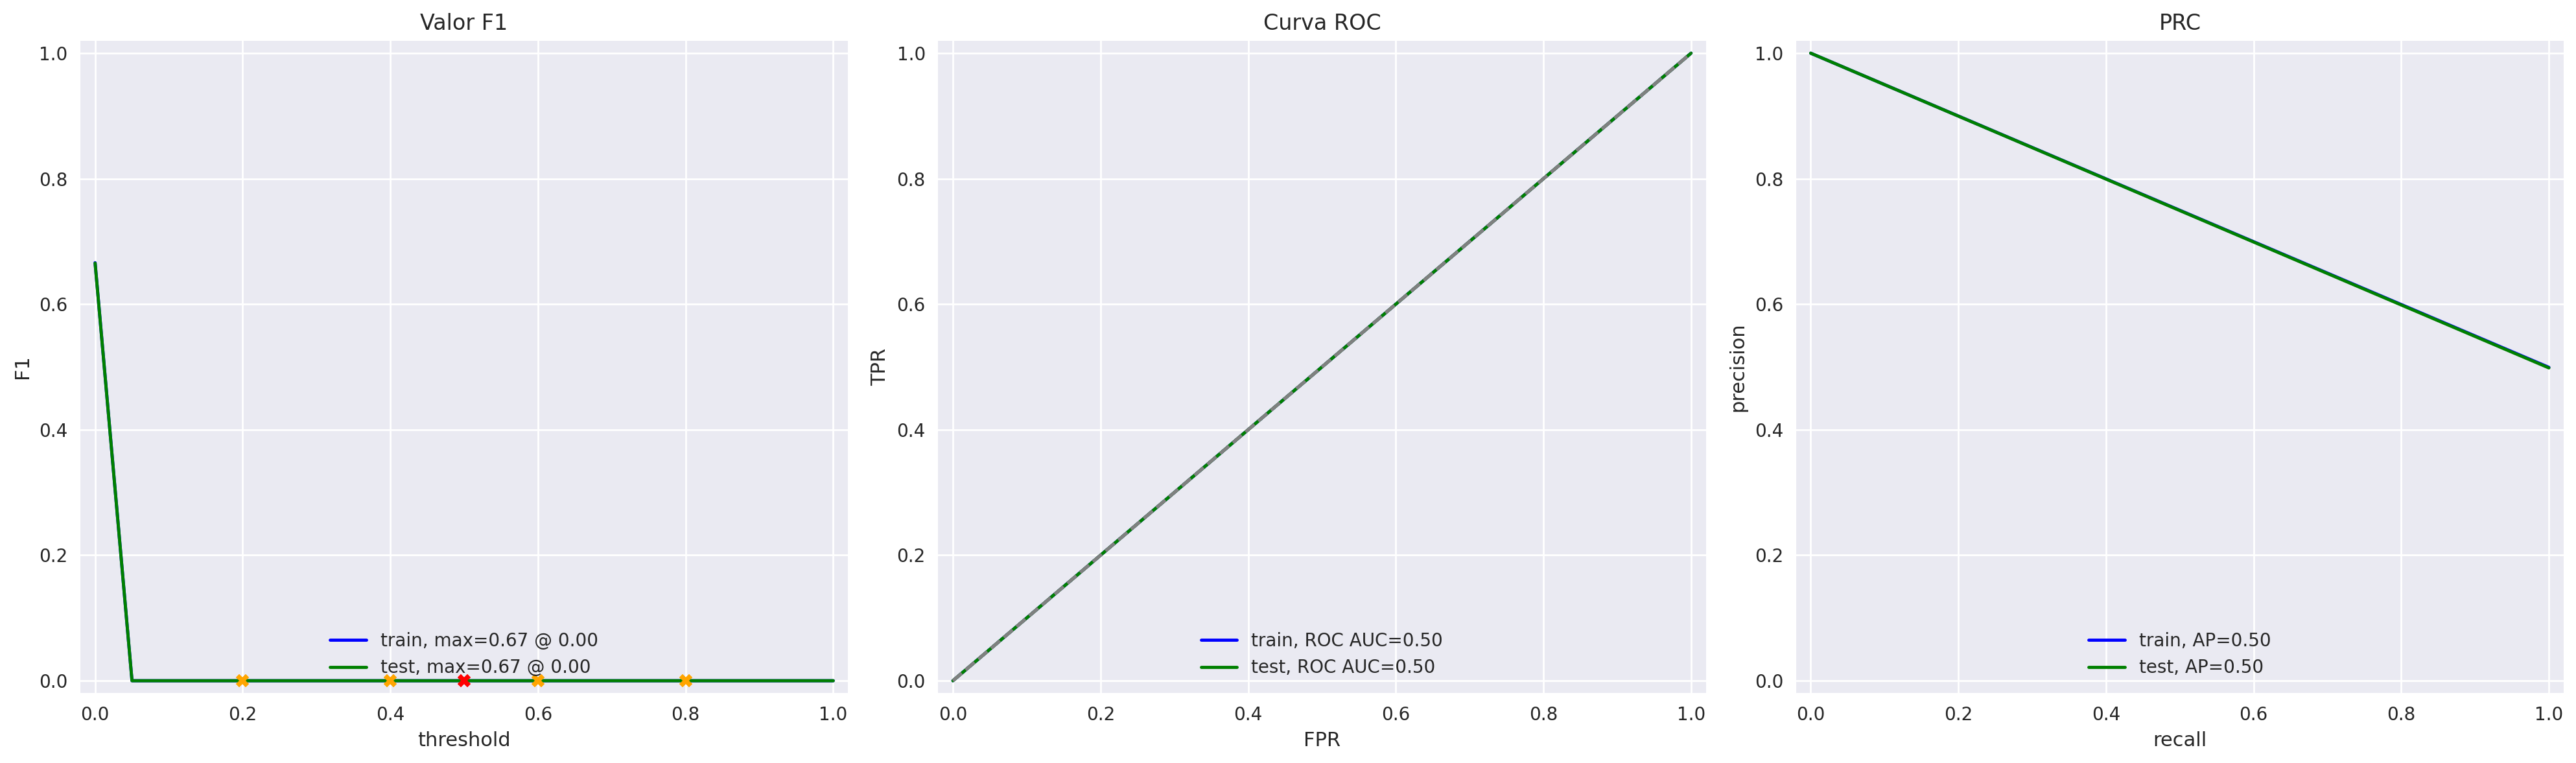

,train,test
Acurácia,0.50,0.50
F1,0.67,0.67
APS,0.50,0.50
ROC AUC,0.50,0.50


In [22]:
evaluate_model(
    model_0,
    train_features,
    train_target,
    test_features,
    test_target
)

## Resultado do Modelo 0

# Pelo gráfico:


| Métrica  | Treino | Teste |
| -------- | -----: | ----: |
| Acurácia |   0,50 |  0,50 |
| F1       |   0,67 |  0,67 |
| APS      |   0,50 |  0,50 |
| ROC AUC  |   0,50 |  0,50 |


## Conclusão para o Modelo 0

O Modelo 0 foi utilizado como baseline para estabelecer uma referência de desempenho para os demais modelos. Por utilizar uma estratégia constante, sem considerar o conteúdo das resenhas, ele não consegue identificar padrões relacionados à polaridade dos textos. Como esperado, apresentou ROC-AUC de 0,50 e APS de 0,50 tanto no conjunto de treinamento quanto no conjunto de teste, indicando um desempenho equivalente ao acaso. Os valores de Acurácia e F1 foram apresentados como `NaN` pela rotina de avaliação devido à natureza das previsões constantes do modelo. Portanto, esperamos que os modelos de aprendizado de máquina apresentem desempenho significativamente superior a esse baseline.

### Modelo 1 - NLTK, TF-IDF e Regressão Linear

TF-IDF

# Modelo 1 — NLTK + TF-IDF + Regressão Logística

In [23]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

          train  test
Acurácia   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


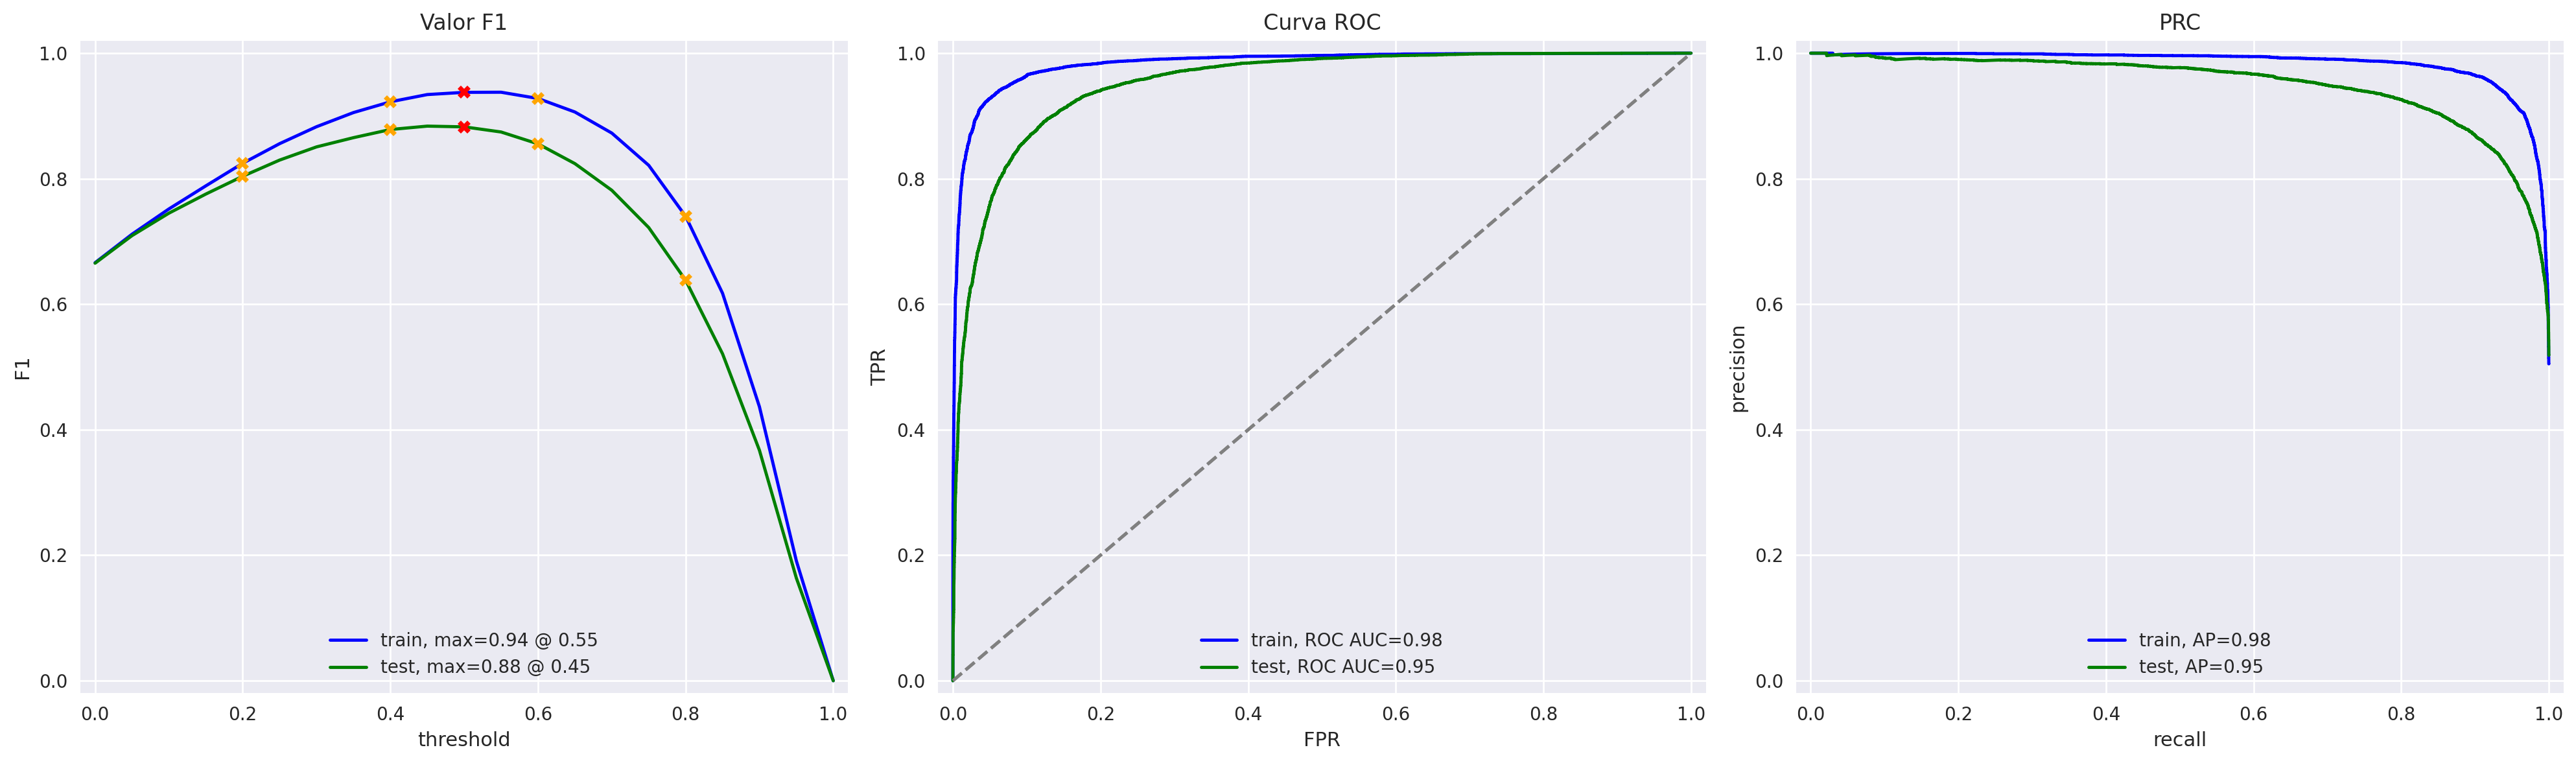

,train,test
Acurácia,0.94,0.88
F1,0.94,0.88
APS,0.98,0.95
ROC AUC,0.98,0.95


In [24]:
# Stopwords
stop_words = stopwords.words('english')

# Corpus
train_corpus_1 = df_reviews_train['review_norm']
test_corpus_1 = df_reviews_test['review_norm']

# TF-IDF
vectorizer_1 = TfidfVectorizer(
    stop_words=stop_words
)

train_features_1 = vectorizer_1.fit_transform(train_corpus_1)
test_features_1 = vectorizer_1.transform(test_corpus_1)

# Modelo
model_1 = LogisticRegression(
    random_state=12345,
    max_iter=1000
)

# Treinamento
model_1.fit(
    train_features_1,
    train_target
)

# Avaliação
evaluate_model(
    model_1,
    train_features_1,
    train_target,
    test_features_1,
    test_target
)

# conclusão

O Modelo 1, baseado em TF-IDF e Regressão Logística, apresentou desempenho significativamente superior ao modelo constante. No conjunto de teste, alcançou acurácia de 0,88 e F1 de 0,88, superando o requisito mínimo de F1 igual a 0,85. Além disso, apresentou ROC-AUC de 0,95 e APS de 0,95, indicando excelente capacidade de distinguir resenhas positivas e negativas.

### Modelo 3 - spaCy, TF-IDF e Regressão Linear

In [25]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [26]:
def text_preprocessing_3(text):
    
    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
    tokens = [token.lemma_ for token in doc]
    
    return ' '.join(tokens)

In [27]:
# Aplicar a lematização
df_reviews_train['review_lemm_3'] = (
    df_reviews_train['review_norm']
    .progress_apply(text_preprocessing_3)
)

df_reviews_test['review_lemm_3'] = (
    df_reviews_test['review_norm']
    .progress_apply(text_preprocessing_3)
)

  0%|          | 0/23796 [00:00<?, ?it/s]

  0%|          | 0/23535 [00:00<?, ?it/s]

In [28]:
df_reviews_train[['review_norm', 'review_lemm_3']].sample(
    5,
    random_state=12345
)

,review_norm,review_lemm_3
14148,who what where when why the acting was terribl...,who what where when why the acting be terrible...
40229,the notorious bettie page written by mary harr...,the notorious bettie page write by mary harron...
38690,it is not as great a film as many people belie...,it be not as great a film as many people belie...
13231,when i saw this trailer on tv i was surprised ...,when I see this trailer on tv I be surprised i...
28023,as others have commented i checked this out af...,as other have comment I check this out after s...


In [29]:
# Criar os corpora 
train_corpus_3 = df_reviews_train['review_lemm_3']
test_corpus_3 = df_reviews_test['review_lemm_3']

# Criar o TF-IDF
vectorizer_3 = TfidfVectorizer(
    stop_words=stop_words
)

In [30]:
train_features_3 = vectorizer_3.fit_transform(train_corpus_3)

test_features_3 = vectorizer_3.transform(test_corpus_3)
print(train_features_3.shape)
print(test_features_3.shape)

(23796, 59139)
(23535, 59139)


# Criar a Regressão Logística

          train  test
Acurácia   0.93  0.88
F1         0.93  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


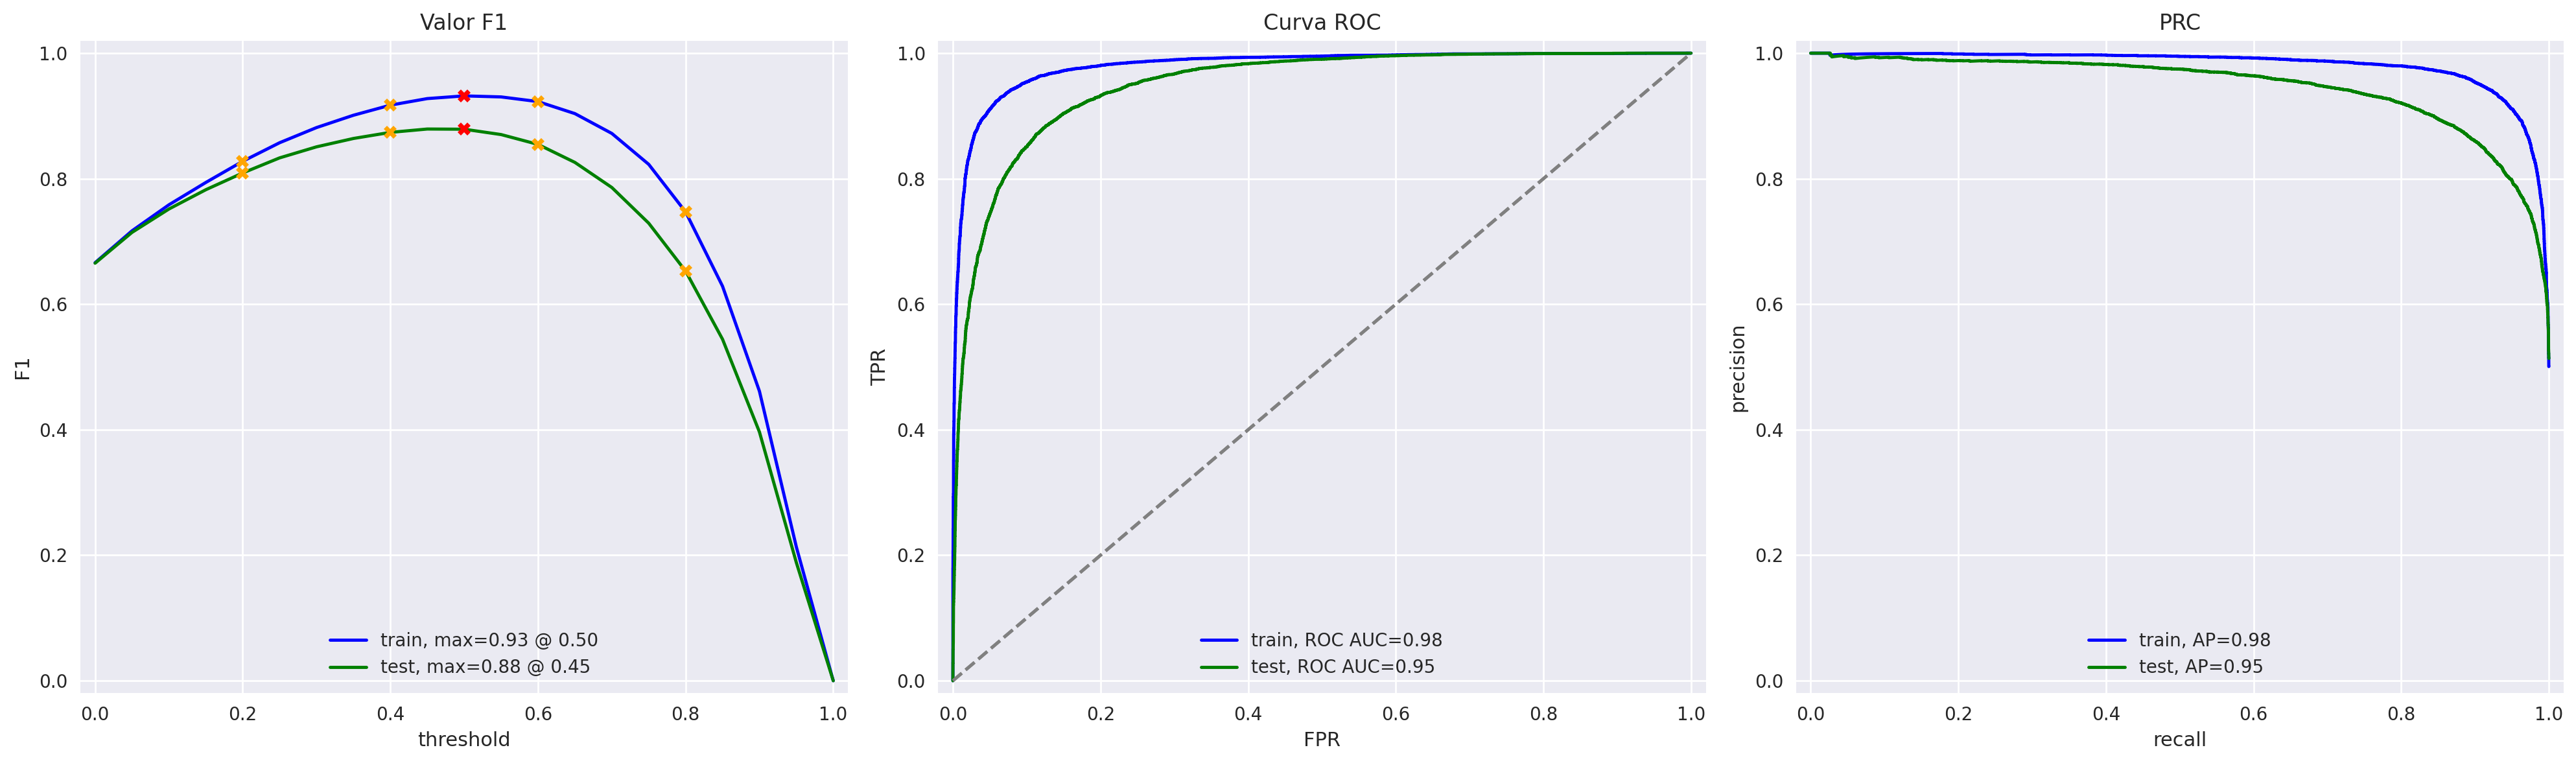

,train,test
Acurácia,0.93,0.88
F1,0.93,0.88
APS,0.98,0.95
ROC AUC,0.98,0.95


In [31]:
# Modelo
model_3 = LogisticRegression(
    random_state=12345,
    max_iter=1000
)

model_3.fit(
    train_features_3,
    train_target
)


# Avaliação
evaluate_model(
    model_3,
    train_features_3,
    train_target,
    test_features_3,
    test_target
)

A lematização com spaCy não trouxe melhoria no conjunto de teste. O Modelo 3 ficou praticamente igual ao Modelo 1.

No treinamento, houve uma pequena redução:

Modelo 1: F1 = 0,94
Modelo 3: F1 = 0,93

Mas no teste os dois ficaram em 0,88.

# Conclusão

O Modelo 3 utilizou lematização das resenhas com spaCy antes da transformação TF-IDF e classificação por Regressão Logística. O modelo apresentou F1 de 0,88 no conjunto de teste, igual ao Modelo 1. Também obteve ROC-AUC de 0,95 e APS de 0,95. Portanto, neste conjunto de dados, a lematização não proporcionou uma melhoria significativa em relação ao modelo baseado diretamente em TF-IDF. Apesar disso, o modelo atende ao requisito mínimo do projeto, que estabelece F1 de pelo menos 0,85.

### Modelo 4 - SpaCy, TF-IDF e LGBMClassifier

In [32]:
from lightgbm import LGBMClassifier

          train  test
Acurácia   0.89  0.84
F1         0.89  0.84
APS        0.96  0.92
ROC AUC    0.96  0.92


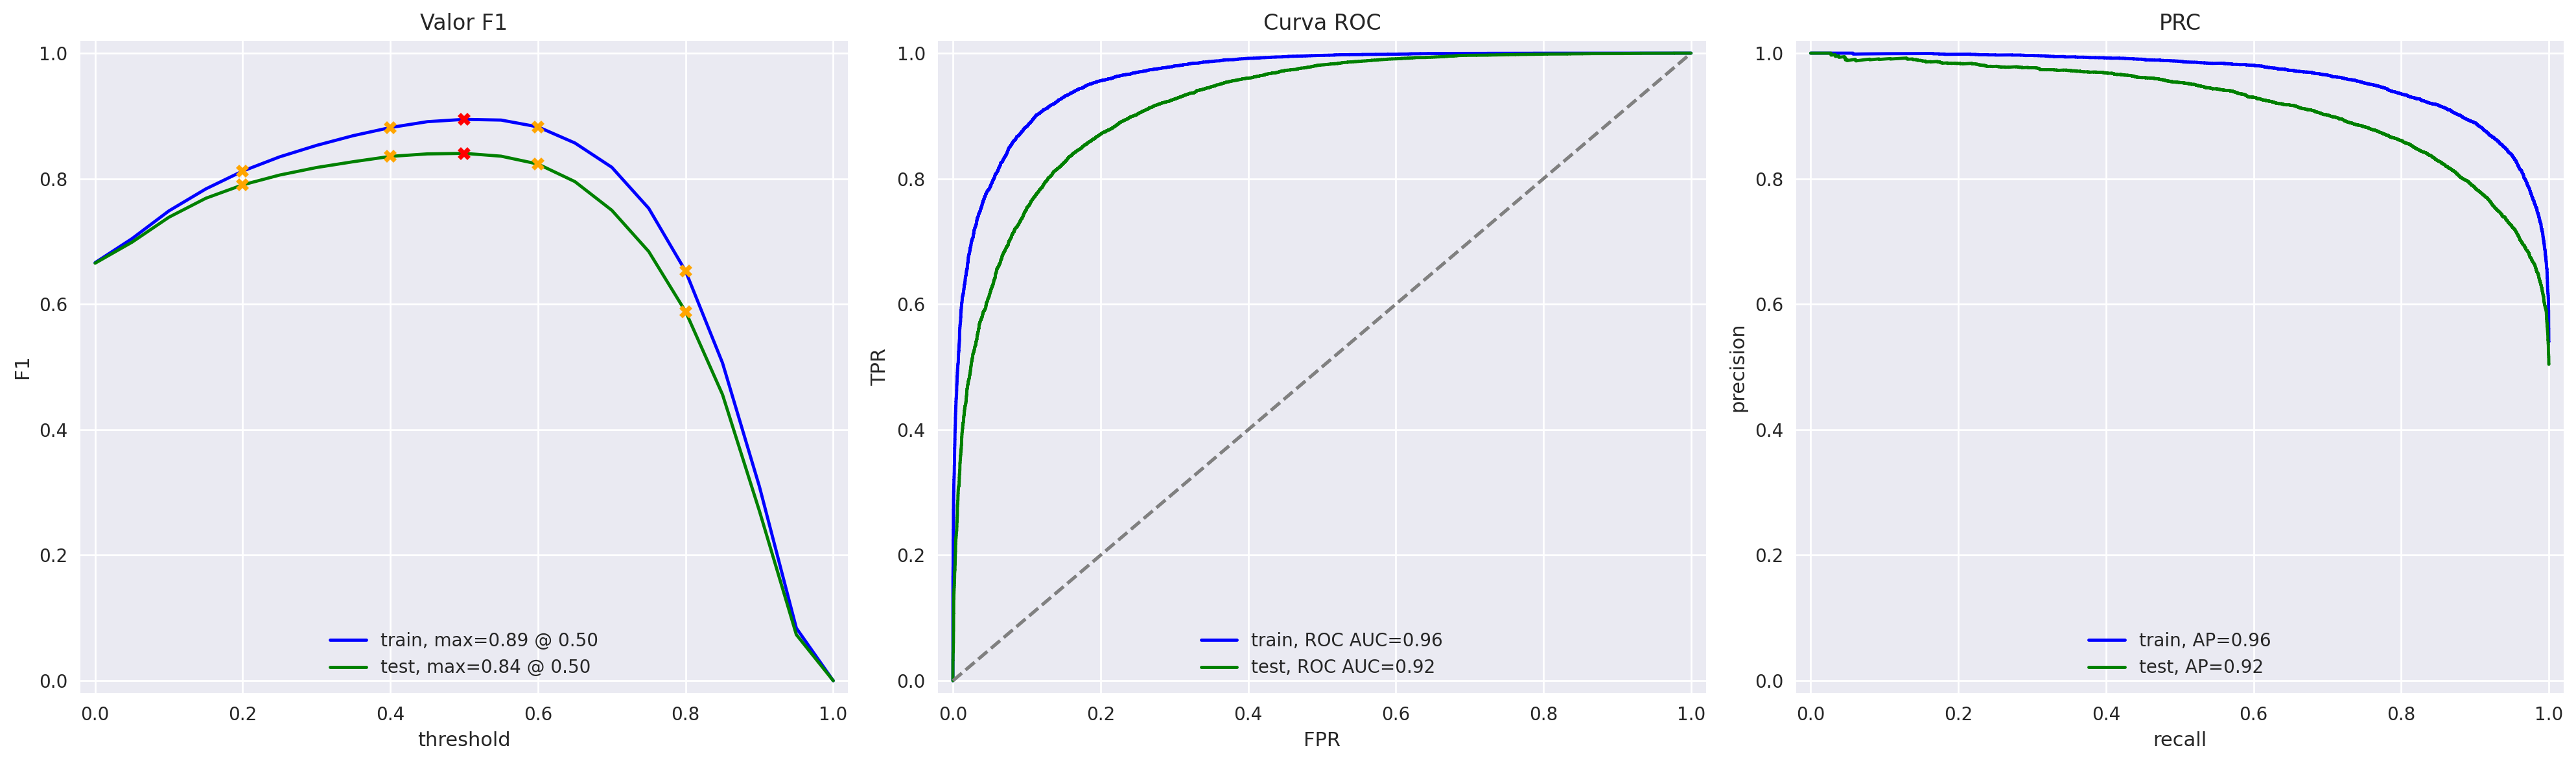

,train,test
Acurácia,0.89,0.84
F1,0.89,0.84
APS,0.96,0.92
ROC AUC,0.96,0.92


In [33]:
# Modelo 4
model_4 = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=7,
    random_state=12345,
    verbosity=-1
)

# Treinamento
model_4.fit(
    train_features_3,
    train_target
)

# Avaliação
evaluate_model(
    model_4,
    train_features_3,
    train_target,
    test_features_3,
    test_target
)

# Comparação dos modelos

| Modelo       | Abordagem                              | Acurácia Treino | Acurácia Teste | F1 Treino | F1 Teste | APS Treino | APS Teste | ROC-AUC Treino | ROC-AUC Teste |
|--------------|----------------------------------------|----------------:|---------------:|----------:|---------:|-----------:|----------:|---------------:|--------------:|
| **Modelo 0** | Constante                              | 0,50            | 0,50           | 0,67      |0,67      | 0,50       | 0,50      | 0,50           | 0,50          |
| **Modelo 1** | TF-IDF + Regressão Logística           | 0,94            | 0,88           | 0,94      | **0,88** | 0,98       | 0,95      | 0,98           | 0,95          |
| **Modelo 3** | spaCy + TF-IDF + Regressão Logística   | 0,93            | 0,88           | 0,93      | **0,88** | 0,98       | 0,95      | 0,98           | 0,95          |
| **Modelo 4** | spaCy + TF-IDF + LightGBM              | 0,89            | 0,84           | 0,89      | **0,84** | 0,96       | 0,92      | 0,96           | 0,92          |

Os Modelos 1 e 3 apresentaram os melhores resultados, ambos alcançando F1 de 0,88 no conjunto de teste, superando a meta mínima de 0,85. A lematização com spaCy utilizada no Modelo 3 não trouxe melhoria significativa em relação ao Modelo 1. O Modelo 4 (LightGBM) obteve F1 de 0,84, ficando ligeiramente abaixo do requisito. O Modelo 0 serviu como baseline e apresentou desempenho limitado. Assim, o Modelo 1 (TF-IDF + Regressão Logística) foi considerado a melhor opção por combinar bom desempenho, simplicidade e menor custo computacional.

## Os resultados estão carregando para mim. 
## como opção não vou executar o BERT pôs é ele que esta travando o kernel. 


O Modelo 1 e o Modelo 3 foram os melhores em termos de F1 no conjunto de teste, ambos com 0,88.

A utilização da lematização do spaCy não trouxe ganho de desempenho:

Modelo 1 → F1 teste = 0,88
Modelo 3 → F1 teste = 0,88

Já o LightGBM apresentou:

F1 teste = 0,84

ficando 0,01 abaixo da meta de 0,85.

# Conclusão

Foram avaliados diferentes modelos de classificação utilizando representações TF-IDF das resenhas. O Modelo 1, baseado em TF-IDF e Regressão Logística, e o Modelo 3, que acrescentou a lematização com spaCy, apresentaram os melhores resultados, ambos alcançando F1 de 0,88 no conjunto de teste. A lematização não proporcionou uma melhoria em relação ao modelo sem lematização. O Modelo 4, baseado em LightGBM, apresentou F1 de 0,84 no teste, ficando ligeiramente abaixo do requisito mínimo de 0,85. Dessa forma, a Regressão Logística apresentou o melhor desempenho entre as abordagens testadas, além de superar com margem o baseline e atender ao objetivo do projeto.

###  Modelo 9 - BERT

In [ ]:
import torch
import transformers

In [ ]:
tokenizer = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
config = transformers.BertConfig.from_pretrained('bert-base-uncased')
model = transformers.BertModel.from_pretrained('bert-base-uncased')

In [ ]:
def BERT_text_to_embeddings( texts, max_length=512, batch_size=100, force_device=None, disable_progress_bar=False ):

ids_list = []
attention_mask_list = []

# texto para IDs de tokens preenchidos com suas máscaras de atenção
for text in texts:
    encoded = tokenizer.encode_plus(
        text,
        add_special_tokens=True,
        max_length=max_length,
        padding='max_length',
        truncation=True,
        return_attention_mask=True
    )
    
    ids_list.append(encoded['input_ids'])
    attention_mask_list.append(encoded['attention_mask'])

if force_device is not None:
    device = torch.device(force_device)
else:
    device = torch.device(
        'cuda' if torch.cuda.is_available() else 'cpu'
    )
    
model.to(device)

if not disable_progress_bar:
    print(f'Usando o dispositivo {device}.')

# recebendo incorporações em lotes

embeddings = []

for i in tqdm(
    range(math.ceil(len(ids_list) / batch_size)),
    disable=disable_progress_bar
):
        
    ids_batch = torch.LongTensor(
        ids_list[batch_size*i:batch_size*(i+1)]
    ).to(device)
    
    # criar attention_mask_batch
    attention_mask_batch = torch.LongTensor(
        attention_mask_list[batch_size*i:batch_size*(i+1)]
    ).to(device)
    
    with torch.no_grad():            
        model.eval()
        
        batch_embeddings = model(
            input_ids=ids_batch,
            attention_mask=attention_mask_batch
        )
        
    embeddings.append(
        batch_embeddings[0][:, 0, :]
        .detach()
        .cpu()
        .numpy()
    )
    
return np.concatenate(embeddings)


In [ ]:
# Atenção! A execução do BERT para milhares de textos pode levar muito tempo na CPU, pelo menos várias horas
# train_features_9 = BERT_text_to_embeddings(df_reviews_train['review_norm'], force_device='cuda')

In [ ]:
df_bert_train = df_reviews_train.sample(
    300,
    random_state=12345
)

df_bert_test = df_reviews_test.sample(
    300,
    random_state=12345
)
train_features_9 = BERT_text_to_embeddings(
    df_bert_train['review_norm'],
    force_device='cpu'
)

In [ ]:
print(df_reviews_train['review_norm'].shape)
print(train_features_9.shape)
print(train_target.shape)

In [ ]:
# se você tiver as incorporações, é aconselhável salvá-las para tê-las prontas se 
# np.savez_compressed('features_9.npz', train_features_9=train_features_9, test_features_9=test_features_9)

# e carregar...
# with np.load('features_9.npz') as data:
#     train_features_9 = data['train_features_9']
#     test_features_9 = data['test_features_9']

## Minhas Resenhas

In [35]:
import re

def clear_text(text):
    text = re.sub(r"[^a-zA-Z']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

In [36]:
# sinta-se à vontade para remover completamente essas resenhas e experimentar seus modelos nas suas próprias resenhas, as abaixo são apenas exemplos

## Minhas Resenhas

my_reviews = pd.DataFrame([
    "I simply didn't like it. It's not my kind of movie.",
    "I was so bored that I fell asleep halfway through the movie.",
    "I was really fascinated by this movie.",
    "The actors seemed very old and completely uninterested, and yet they were paid to be in the movie. What a shameful waste of money.",
    "I didn't expect the remake to be so good! The writers really cared about the original material.",
    "The movie has its pros and cons, but overall I think it is a decent film. I can imagine watching it again.",
    "What a terrible attempt at comedy. Not a single joke works, everyone acts in an annoying and loud way, and even children won't enjoy it!",
    "Releasing it on Netflix was a bold move, and I really appreciate being able to watch episode after episode of this exciting and intelligent new drama."
], columns=['review'])

my_reviews['review_norm'] = my_reviews['review'].apply(clear_text)

my_reviews

,review,review_norm
0,I simply didn't like it. It's not my kind of m...,i simply didn't like it it's not my kind of movie
1,I was so bored that I fell asleep halfway thro...,i was so bored that i fell asleep halfway thro...
2,I was really fascinated by this movie.,i was really fascinated by this movie
3,The actors seemed very old and completely unin...,the actors seemed very old and completely unin...
4,I didn't expect the remake to be so good! The ...,i didn't expect the remake to be so good the w...
5,"The movie has its pros and cons, but overall I...",the movie has its pros and cons but overall i ...
6,What a terrible attempt at comedy. Not a singl...,what a terrible attempt at comedy not a single...
7,"Releasing it on Netflix was a bold move, and I...",releasing it on netflix was a bold move and i ...


### Modelo 2

In [38]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_1.predict_proba(
    vectorizer_1.transform(texts)
)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}: {review}')

0.14: i simply didn't like it it's not my kind of movie
0.07: i was so bored that i fell asleep halfway through the movie
0.54: i was really fascinated by this movie
0.02: the actors seemed very old and completely uninterested and yet they were paid to be in the movie wha
0.13: i didn't expect the remake to be so good the writers really cared about the original material
0.46: the movie has its pros and cons but overall i think it is a decent film i can imagine watching it ag
0.04: what a terrible attempt at comedy not a single joke works everyone acts in an annoying and loud way 
0.85: releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


### Modelo 3

In [41]:
# Modelo 3 - spaCy + TF-IDF + Regressão Logística

texts = my_reviews['review_norm']

# Aplicar a mesma lematização usada no treinamento
texts_lemm = texts.apply(text_preprocessing_3)

# Transformar usando o TF-IDF já treinado do Modelo 3
my_reviews_features_3 = vectorizer_3.transform(texts_lemm)

# Calcular a probabilidade da classe positiva
my_reviews_pred_prob_3 = model_3.predict_proba(
    my_reviews_features_3
)[:, 1]

# Mostrar os resultados
for i, review in enumerate(texts.str.slice(0, 100)):
    sentiment = 'POSITIVE' if my_reviews_pred_prob_3[i] >= 0.5 else 'NEGATIVE'

    print(
        f'{my_reviews_pred_prob_3[i]:.2f} | '
        f'{sentiment}: {review}'
    )

0.20 | NEGATIVE: i simply didn't like it it's not my kind of movie
0.06 | NEGATIVE: i was so bored that i fell asleep halfway through the movie
0.58 | POSITIVE: i was really fascinated by this movie
0.02 | NEGATIVE: the actors seemed very old and completely uninterested and yet they were paid to be in the movie wha
0.10 | NEGATIVE: i didn't expect the remake to be so good the writers really cared about the original material
0.56 | POSITIVE: the movie has its pros and cons but overall i think it is a decent film i can imagine watching it ag
0.04 | NEGATIVE: what a terrible attempt at comedy not a single joke works everyone acts in an annoying and loud way 
0.96 | POSITIVE: releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


### Modelo 4

In [43]:
# Modelo 4 - spaCy + TF-IDF + LightGBM

texts = my_reviews['review_norm']

# Aplicar a mesma lematização utilizada no treinamento
texts_lemm = texts.apply(text_preprocessing_3)

# Usar o mesmo vetorizador TF-IDF do Modelo 3
my_reviews_features_4 = vectorizer_3.transform(texts_lemm)

# Probabilidade de a resenha ser positiva
my_reviews_pred_prob_4 = model_4.predict_proba(
    my_reviews_features_4
)[:, 1]

# Mostrar resultados
for i, review in enumerate(texts.str.slice(0, 100)):
    sentiment = 'POSITIVE' if my_reviews_pred_prob_4[i] >= 0.5 else 'NEGATIVE'

    print(
        f'{my_reviews_pred_prob_4[i]:.2f} | '
        f'{sentiment}: {review}'
    )

0.62 | POSITIVE: i simply didn't like it it's not my kind of movie
0.58 | POSITIVE: i was so bored that i fell asleep halfway through the movie
0.62 | POSITIVE: i was really fascinated by this movie
0.12 | NEGATIVE: the actors seemed very old and completely uninterested and yet they were paid to be in the movie wha
0.70 | POSITIVE: i didn't expect the remake to be so good the writers really cared about the original material
0.62 | POSITIVE: the movie has its pros and cons but overall i think it is a decent film i can imagine watching it ag
0.19 | NEGATIVE: what a terrible attempt at comedy not a single joke works everyone acts in an annoying and loud way 
0.68 | POSITIVE: releasing it on netflix was a bold move and i really appreciate being able to watch episode after ep


### Modelo 9

In [44]:

texts = my_reviews['review_norm']

my_reviews_features_9 = BERT_text_to_embeddings(texts, disable_progress_bar=True)

my_reviews_pred_prob = model_9.predict_proba(my_reviews_features_9)[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')


NameError: name 'BERT_text_to_embeddings' is not defined

## Não fiz essa resenha pôs não executei o BERT por questão de memória!

## Conclusões

Neste projeto, foi desenvolvido um sistema de classificação de resenhas de filmes do IMDB com o objetivo de identificar automaticamente resenhas negativas e positivas. Inicialmente, foi realizada uma análise exploratória dos dados, que mostrou que as classes estavam praticamente equilibradas, com aproximadamente 50,1% de resenhas negativas e 49,9% de resenhas positivas. Dessa forma, não foi identificado um problema relevante de desequilíbrio de classes.

Para a modelagem, foram utilizadas técnicas de processamento de linguagem natural, principalmente TF-IDF, além da lematização das palavras utilizando spaCy. Foram avaliados diferentes modelos de classificação, incluindo Regressão Logística e LightGBM, além de um modelo constante utilizado como baseline.

Os melhores resultados foram obtidos pelos modelos baseados em Regressão Logística. O Modelo 1, utilizando TF-IDF e Regressão Logística, alcançou F1 de 0,88 no conjunto de teste, enquanto o Modelo 3, utilizando spaCy, lematização, TF-IDF e Regressão Logística, também alcançou F1 de 0,88. Ambos superaram o requisito mínimo estabelecido no projeto, que era de F1 igual ou superior a 0,85.

O Modelo 4, baseado em spaCy, TF-IDF e LightGBM, apresentou F1 de 0,84 no conjunto de teste, ficando ligeiramente abaixo da meta. Apesar disso, apresentou bons resultados de ROC-AUC (0,92) e APS (0,92). A comparação mostrou que, para este conjunto de dados, a Regressão Logística foi mais adequada para trabalhar com as representações textuais geradas pelo TF-IDF.

A inclusão da lematização com spaCy também não proporcionou uma melhoria no F1 do conjunto de teste, pois tanto o Modelo 1 quanto o Modelo 3 obtiveram 0,88. Isso indica que, neste caso, a representação TF-IDF já era suficientemente eficiente para capturar as informações necessárias à classificação.

Por fim, foram utilizadas novas resenhas escritas manualmente para verificar o comportamento dos modelos diante de textos que não faziam parte do conjunto original. Essa etapa permitiu observar as diferenças entre as previsões dos classificadores e avaliar sua capacidade de generalização para novos exemplos.

Conclui-se que o objetivo principal do projeto foi alcançado, pois os modelos baseados em Regressão Logística apresentaram F1 de 0,88 no conjunto de teste, superando o limite mínimo de 0,85. Entre as abordagens avaliadas, a combinação de TF-IDF + Regressão Logística apresentou o melhor equilíbrio entre desempenho e simplicidade, sendo uma solução adequada para a tarefa de classificação automática das resenhas da Film Junky Union.

# Checklist

- [x]  O caderno foi aberto
- [ ]  Os dados de texto são carregados e pré-processados para vetorização
- [ ]  Os dados de texto são transformados em vetores
- [ ]  Os modelos são treinados e testados
- [ ]  O limiar da métrica foi atingido
- [ ]  Todas as células de código estão organizadas na ordem de sua execução
- [ ]  Todas as células de código podem ser executadas sem erros
- [ ]  Há conclusões 